In [115]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# find the project folder and your RQ1B outputs
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
out = root / "outputs" / "rq1b"
fig = out / "figures"

dispersion = pd.read_csv(out / "rq1b_employment_dispersion_by_year.csv")
trend = pd.read_csv(out / "rq1b_employment_trend_tests.csv")
decomp = pd.read_csv(out / "rq1b_between_within_country.csv")
quintiles = pd.read_csv(out / "rq1b_change_by_starting_quintile.csv")

# RQ1B: Are employment gaps between EU regions narrowing?

## Introduction
This section tests whether employment rates across EU regions became more similar between 2016 and 2024 (sigma convergence). The data is the Eurostat employment rate for people aged 20–64 in each NUTS 2 region. We measure the spread between regions each year using the standard deviation (SD), the coefficient of variation (CV = SD ÷ mean × 100) and the gap between the 90th- and 10th-percentile regions (P90 − P10). If these measures fall over time, regions are converging.

To make sure the result is not caused by regions entering or leaving the data, we use three samples: the master panel (237–244 regions), a constant sample of 236 regions with data in every year, and the team's balanced panel of 224 regions.

**Short answer: yes.** Employment gaps between EU regions narrowed clearly between 2016 and 2024.

## 1. Dispersion by year
The table shows the spread of regional employment rates in each year on the balanced panel. The average employment rate rose from 69.6% to 75.6%, while the standard deviation fell from 8.34 to 7.12 points. Because the spread fell even as the average rose, the regions really did become more alike.

In [116]:
from IPython.display import HTML
cols = ["year", "mean", "std_dev", "coef_variation_pct", "p10", "p90", "p90_minus_p10"]
display(HTML(dispersion[dispersion["sample"] == "balanced"][cols].round(2).to_html(index=False)))

year,mean,std_dev,coef_variation_pct,p10,p90,p90_minus_p10
2016,69.63,8.34,11.98,57.14,79.07,21.93
2017,70.86,8.18,11.54,58.79,79.90,21.11
2018,71.95,8.11,11.28,60.63,80.67,20.04
2019,72.72,8.01,11.01,61.49,81.00,19.51
2020,71.92,7.94,11.03,59.89,80.41,20.52
2021,72.72,8.09,11.12,61.13,81.67,20.54
2022,74.37,7.82,10.51,63.43,82.94,19.51
2023,75.05,7.54,10.04,65.30,83.00,17.70
2024,75.60,7.12,9.42,66.83,83.47,16.64


## 2. The coefficient of variation fell by about a fifth
The chart below shows the CV for all three samples. On the balanced panel it fell from 12.0% in 2016 to 9.4% in 2024, a drop of 21%. The three lines move almost together, so the result does not depend on which regions are included. The fall paused in 2020–2021, when COVID-19 hit employment and Eurostat changed its Labour Force Survey method, and it was fastest in 2022–2024.

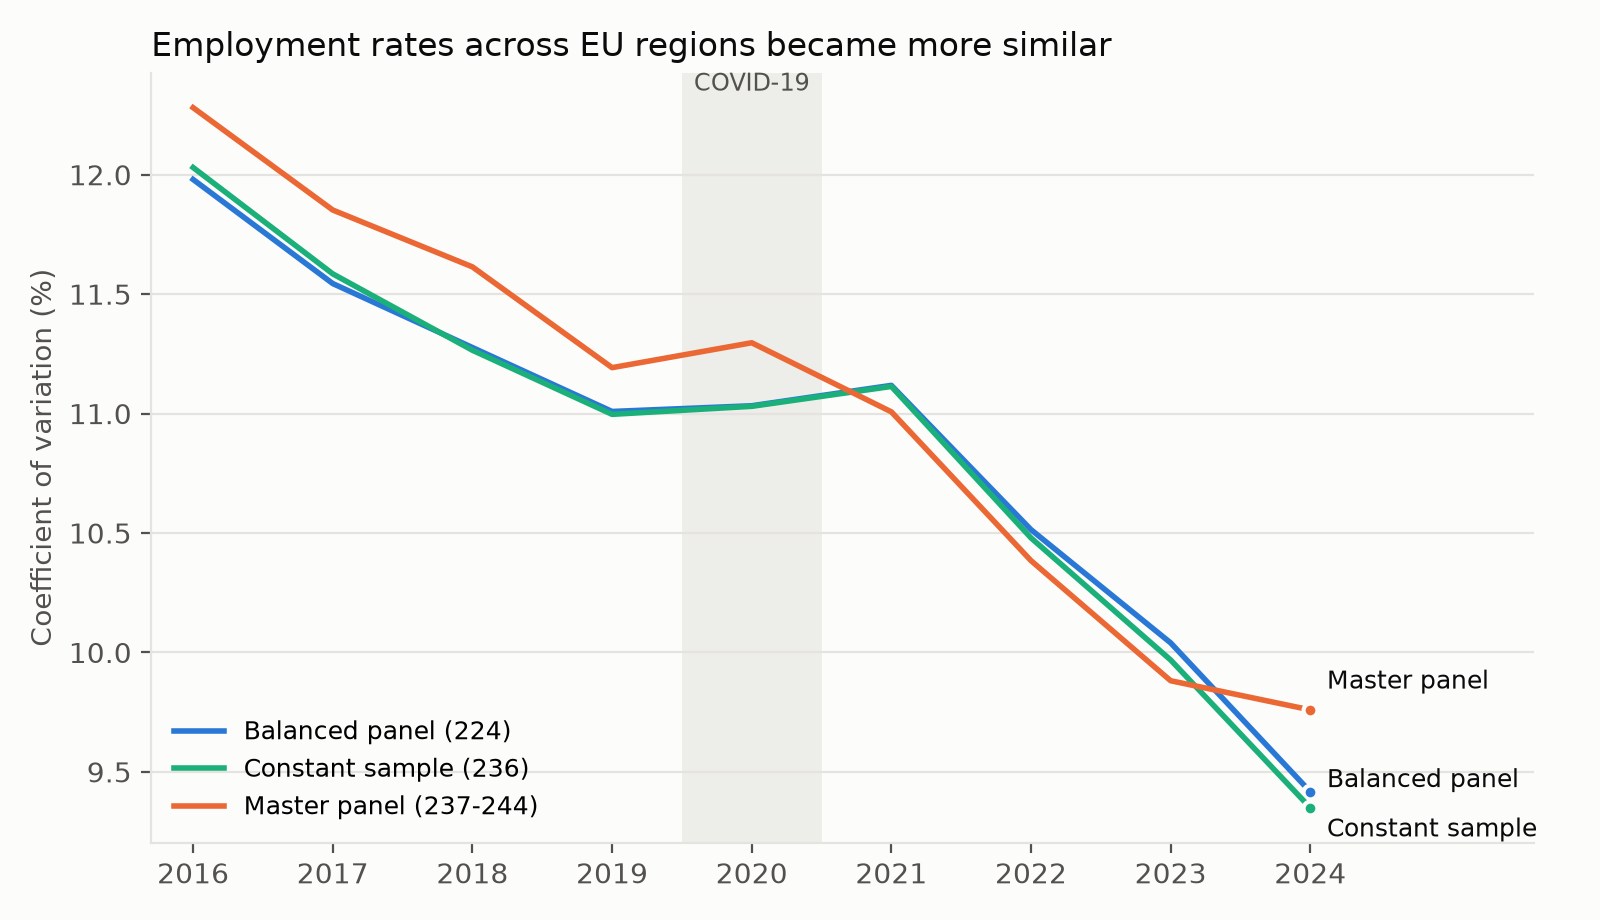

In [117]:
display(Image(filename=fig / "fig1_employment_cv_by_year.png", width=800))


## 3. Is the fall statistically meaningful?
To test the trend, we fitted a straight line to the CV over the nine years. The slope is negative in all three samples (about −0.27 to −0.31 points per year), and the p-values are well below 0.01. With only nine yearly values, these tests support the result rather than prove it on their own.

In [118]:
cols = ["sample", "value_2016", "value_2024", "pct_change_2016_2024", "ols_slope_per_year", "ols_p_value"]
display(HTML(trend[trend["measure"] == "coef_variation_pct"][cols].round(4).to_html(index=False)))

sample,value_2016,value_2024,pct_change_2016_2024,ols_slope_per_year,ols_p_value
balanced,11.9801,9.4167,-21.3965,-0.2697,0.0001
constant,12.0301,9.3496,-22.2814,-0.2838,0.0001
master,12.2807,9.7595,-20.5299,-0.3107,0.0000


## 4. The weakest regions gained the most
The chart below shows the 10th percentile (weaker regions), the median and the 90th percentile (strongest regions). The weaker regions gained 9.7 percentage points, while the strongest gained only 4.4. As a result, the gap between them shrank from 21.9 to 16.6 points. Convergence came from the bottom catching up, not from the top falling.

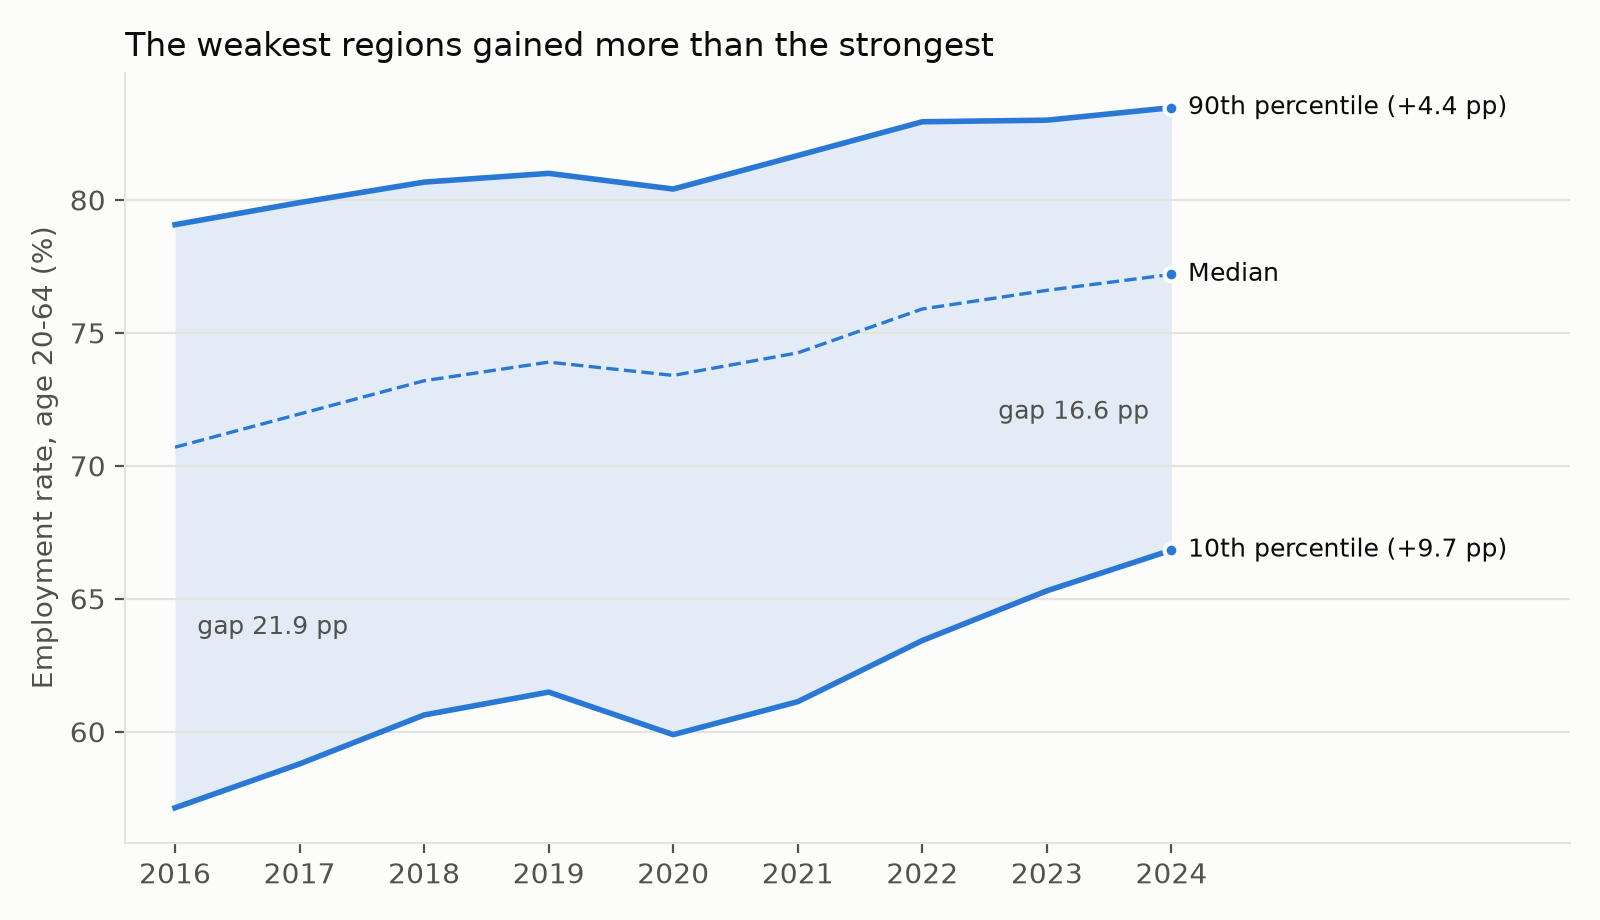

In [119]:
display(Image(filename=fig / "fig2_employment_p10_p90_band.png", width=800))

## 5. Gaps between countries vs gaps within countries
The total spread can be split into differences between countries (national averages) and differences within countries (regions around their own national average). The bar chart shows that the between-country part fell from 42.6 to 26.7, while the within-country part barely changed (26.7 to 23.8). About 85% of the narrowing came from low-employment countries such as Greece and Croatia catching up with the EU average. Gaps inside countries such as Italy and Spain stayed almost as wide as before.

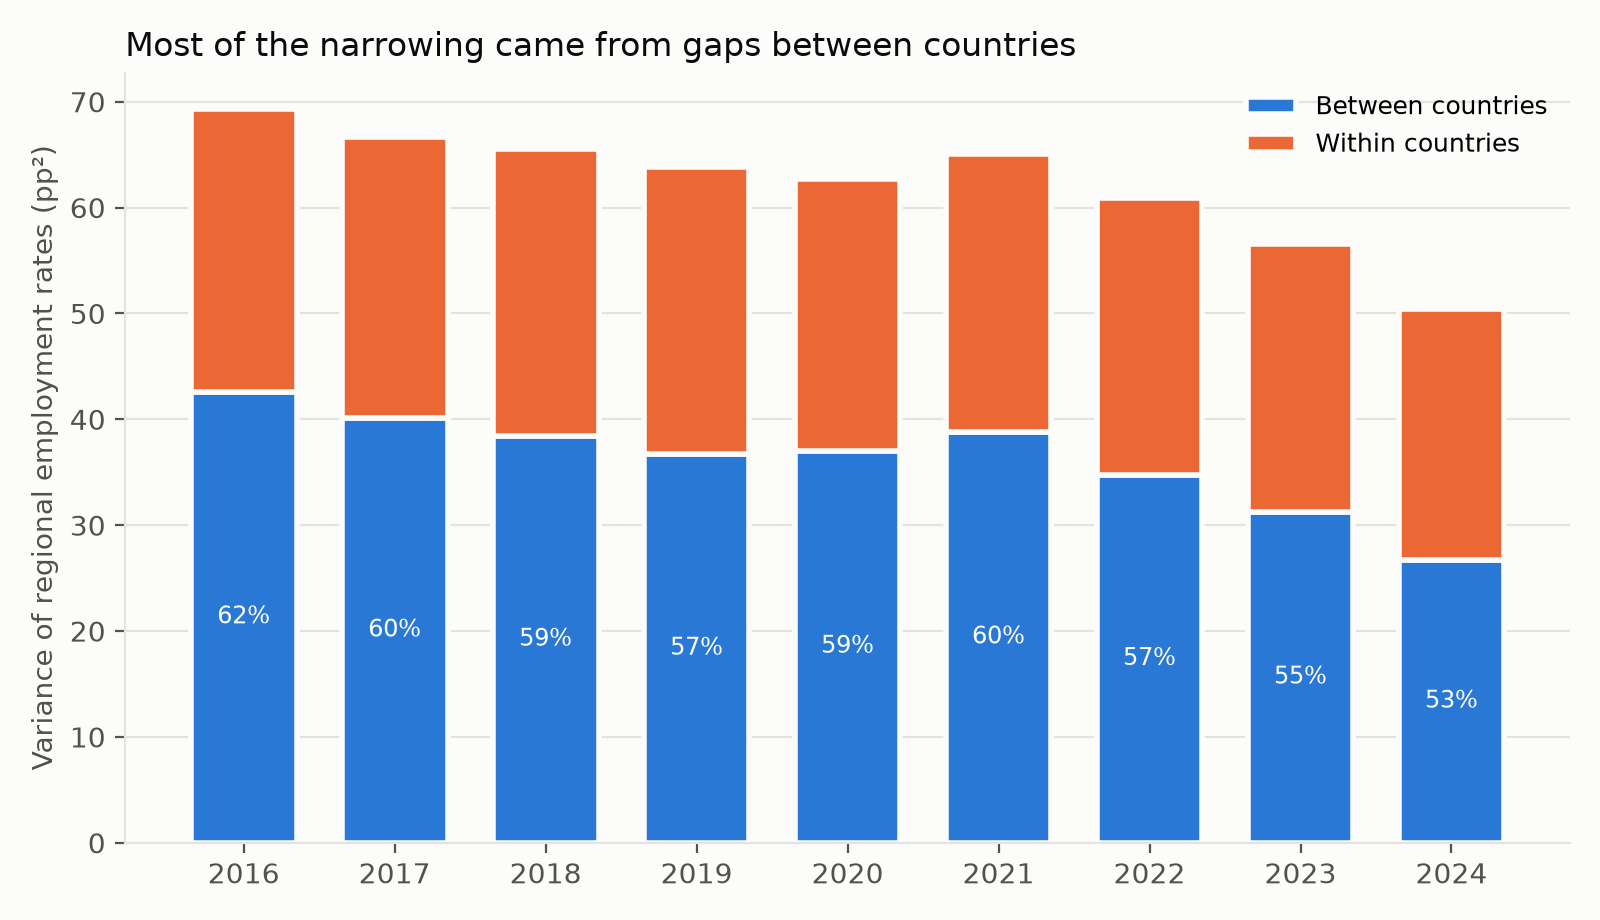

year,total_variance,between_country_variance,within_country_variance,between_country_share_pct,within_country_share_pct
2016,69.3,42.6,26.7,61.5,38.5
2017,66.6,40.1,26.5,60.2,39.8
2018,65.5,38.4,27.2,58.6,41.4
2019,63.8,36.7,27.1,57.5,42.5
2020,62.7,37.0,25.6,59.1,40.9
2021,65.1,38.8,26.3,59.6,40.4
2022,60.9,34.7,26.1,57.1,42.9
2023,56.5,31.2,25.3,55.3,44.7
2024,50.4,26.7,23.8,52.9,47.1


In [120]:
display(Image(filename=fig / "fig3_between_within_country_variance.png", width=800))
display(HTML(decomp.round(1).to_html(index=False)))

## 6. Did lower-starting regions gain more?
Here the regions are split into five equal groups by their 2016 employment rate. The lowest group gained 8.2 points on average, while the highest gained only 2.7. Each group gained less than the one below it, which confirms that the weaker regions caught up.

In [121]:
display(HTML(quintiles.round(2).to_html(index=False)))

quintile_2016,regions,mean_2016,mean_2024,mean_change_pp
Q1 lowest,46,56.53,64.76,8.23
Q2,45,66.87,74.66,7.79
Q3,43,70.75,77.13,6.39
Q4,45,74.76,79.42,4.65
Q5 highest,45,79.60,82.32,2.72


The scatter plot shows each region's 2016 employment rate against its change up to 2024. The line slopes downward (slope −0.22): a region that started 10 points lower gained about 2.2 points more. Greek regions such as Dytiki Elláda gained the most (about +16 points). A few regions still fell behind, such as Nord-Est in Romania (−5 points), and some southern Italian regions remain at the bottom.

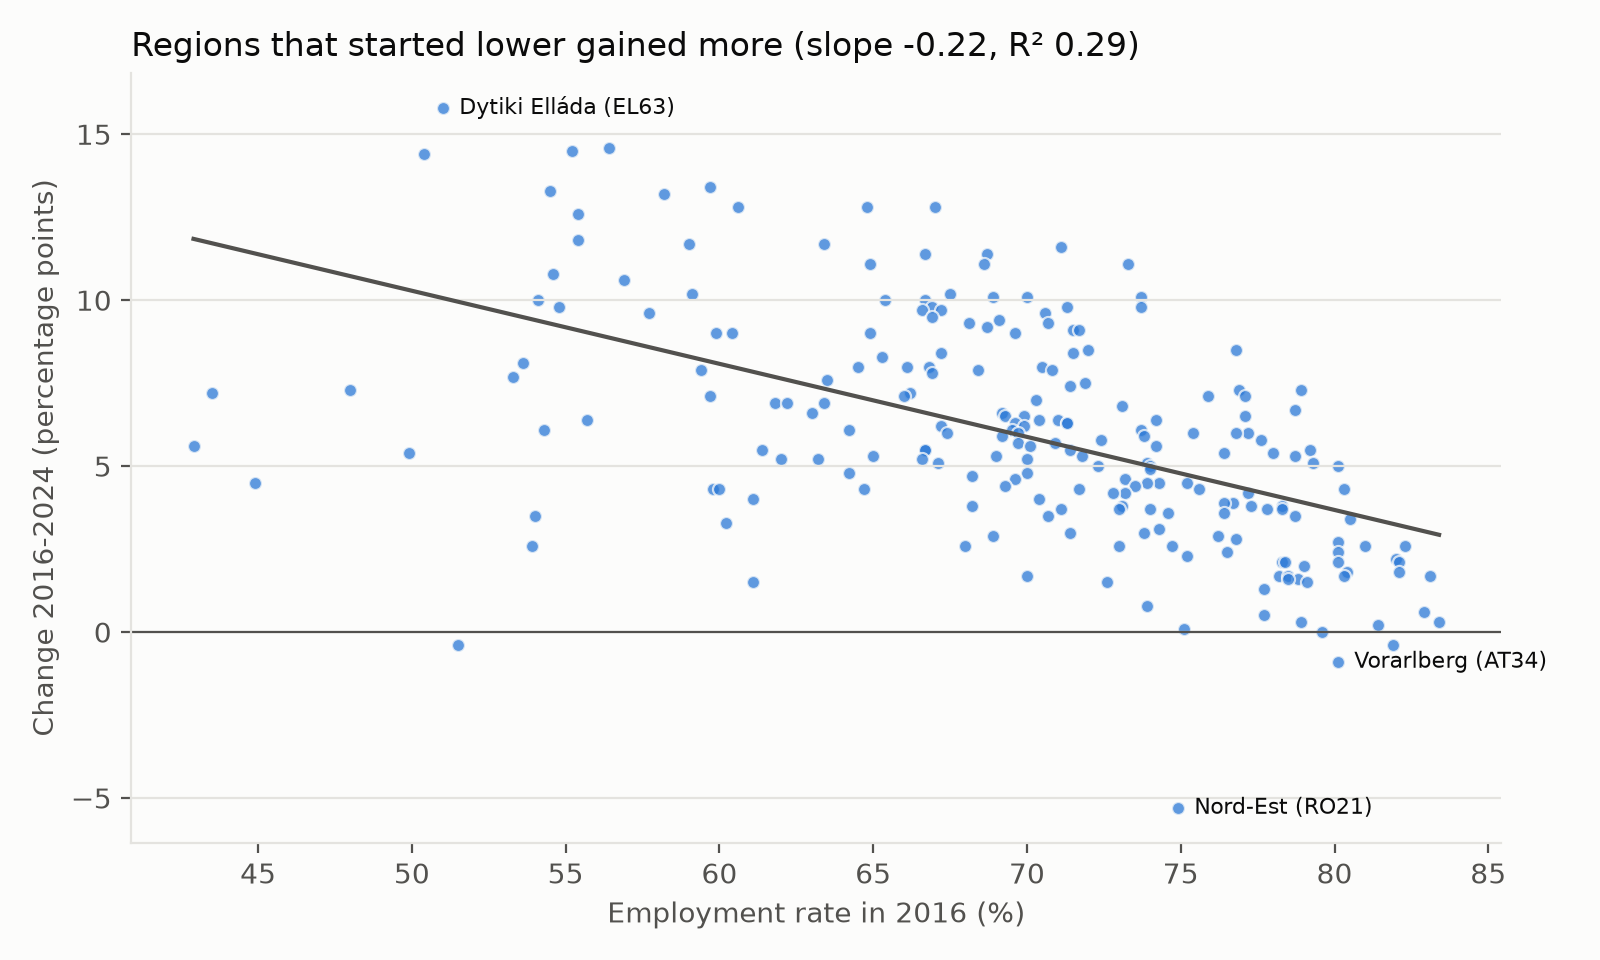

In [122]:
display(Image(filename=fig / "fig4_start_level_vs_change.png", width=800))

## 7. Robustness: the 2021 change in survey method
In 2021 Eurostat changed how the Labour Force Survey is run, so almost every region has a "break" flag that year. If the narrowing were only caused by this change, the CV would drop in one step at 2021. The table shows it did the opposite: the CV fell under the old method (2016–2020), rose slightly in the break year, and fell again under the new method (2021–2024).

In [123]:
breaks = pd.read_csv(out / "rq1b_break_in_series_check.csv")
display(HTML(breaks[breaks["sample"] == "balanced"].round(3).to_html(index=False)))

sample,period,cv_start,cv_end,cv_change,cv_change_per_year
balanced,2016-2020 (old LFS method),11.980,11.033,-0.947,-0.237
balanced,2020-2021 (break year),11.033,11.118,0.085,0.085
balanced,2021-2024 (new LFS method),11.118,9.417,-1.701,-0.567


## Conclusion
Employment gaps between EU regions narrowed between 2016 and 2024. The coefficient of variation fell by about 21%, the gap between weak and strong regions shrank by 5 points, and the result holds in all three samples and across the 2021 change in survey method. Most of the convergence came from lower-employment countries catching up as a whole, while differences inside countries changed little. A group of low-employment regions, mainly in southern Italy and the EU's outermost regions, remains far behind.

**Limitations:** each region counts equally regardless of population, the series covers only nine years, and it includes both a pandemic and a break in the survey method.